This notebook defines the HVGs and Latent Dimensions used across our models using a simple linear model PCA. Additionally, we test PCA on our dataset to obtain an initial insight on it.


# Imports

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import scanpy as sc 
import anndata as ad
import matplotlib.pyplot as plt
import seaborn as sns


# Metrics
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from scipy.stats import entropy
import scib

# warnings
import warnings
warnings.filterwarnings("ignore")
sc.settings.verbosity = 0

# Evaluation Metrics

Evaluation will be done on a random 10.000 cell subsample for faster computation times. Despite it being randomly decided, a seed will be defined at each of this splits in order to ensure fairness across all the different methods.

As for the number of epochs, methods such as scVI use a heuristic approach for deciding it. For other methods we will simply apply a large number of epochs with Early Stopping to avoid potential overfitting.

The metrics we will use to evaluate the model will be applied at latent space level.They will be used to asses the quality of preserving cell-type identity as well as integrating patient samples. They are taken from some of the papers in the literature such as the Benchmarking paper [M.D. Luecken et. Al.](https://www.nature.com/articles/s41592-021-01336-8).
These are:

- **[Adjusted Rand Index (ARI)](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html)**:  Evaluates the similarity between two clustering assignments. Takes the Rand Index (RI) which computes the percentage of correct decisions comparing the predicted clusters to the true labels. In our case, we compare to the true cell-type labels. However, random assignments could have positive values, which is addressed by Adjusted Rand Index. Returns a value between -1 and 1. 1 means perfect classification, 0 corresponds to random cluster assignment

- **[Normalized Mutual Information (NMI)](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.normalized_mutual_info_score.html)**: Mutual Information splits according to clusters and according to class labels. Then, it quantifies how these two splittings agree with each other. However, MI gets large if the number of clusters is large. Therefore, this number is normalized to be between 0 (no mutual information) and 1 (perfect correlation). The higher the better

- **[Average Silhouette Width (ASW)](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html)**: Measures how close an element is to its own cluster while comparing to its other clusters. Returns a value between -1 and 1, where negative values will correspond to when a sample has been assigned to the wrong cluster, positive values indicate good clustering. Values close to 0 are for overlapping clusters.

    The intepretation for this value depends on whether if we want to inspect quality of preserving cell-type identity or integrating patient samples.
    *ASW (cell):* The grouping variable will be the cell-type, we want this value to be high as cells of the same type should form isolated clusters in latent space.
    *ASW(patient):* If this value is high, it means that cells are clustering by patient rather than by biology elements.Therefore we want values closer to 0, as patients contain technical effects, which are usually unwanted (technical effects could be being inspected by a different doctor, different hospital, different times...)

- **Batch Entropy**: Measures the local mixing of a label in the k-nearest neighbor (kNN) graph around each cell. For every cell, the algorithm creates a neighborhood of its k nearest neighbors. (In the below function we use k=50, this will be the same for all models). A low value means that a cell neighborhood has cells from a single label.This can be used to compute for patients -> 'labels=adata.obs["batch_run"]' or 'labels=adata.obs["batch_run"]' are some of the possible options. 

    Our current batch entropy evaluates K=50 neighbors, as we have less number of patients and batch runs, is is possible that the theoretical maximum is slightly lower than 1, we will compute it so we can use it for reference when we obtain values.

In [2]:
# Batch entropy, will be used later in the different function
def compute_entropy(X,labels, k=50, normalize = True):
    nn = NearestNeighbors(n_neighbors=k+1, n_jobs=-1).fit(X)
    indices = nn.kneighbors(X, return_distance=False)[:, 1:]

    labels = np.asarray(labels)
    n_classes = len(np.unique(labels))

    # Normalizing by log(n_classes), max entropy is 1.0
    base = n_classes if (normalize and n_classes > 1) else None

    entropies = [entropy(pd.Series(labels[nbrs]).value_counts(normalize=True), base = base) for nbrs in indices]
    return np.mean(entropies)

# Loading Data

In [3]:
# processing
from data.load_data import load_wu2021, first_col, SEED, N_CELLS

def find_project_root(start=None):
    try:
        start = Path(start or __file__).resolve()   
    except NameError:
        start = Path.cwd().resolve()                
    for parent in [start] + list(start.parents):
        if (parent / "data").exists() or (parent / "README.md").exists():
            return parent
    raise FileNotFoundError("Could not find project root containing 'data/' or README.md.")

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data"
H5AD_PATH = DATA_DIR / "wu_2021_breast_cancer.h5ad"
GEO_DIR = DATA_DIR / "geo_data"

adata = load_wu2021()

In [4]:
# Same processing as before
def is_integer_counts(X, n=500):
    sub = X[:n].toarray() if hasattr(X[:n], "toarray") else np.asarray(X[:n])
    return bool(np.all(sub >= 0) and np.allclose(sub, np.round(sub)))

if not is_integer_counts(adata.X):
    if adata.raw is not None:
        adata = adata.raw.to_adata()

# Map Ensembl IDs to Gene Names if present
if "feature_name" in adata.var:
    adata.var["ensembl_id"] = adata.var_names
    adata.var_names = adata.var["feature_name"].astype(str)

adata.var_names_make_unique()

# Standardize Column Metadata
def first_col(obs, candidates):
    for c in candidates:
        if c in obs.columns:
            return c
    raise KeyError(f"None of {candidates} found in obs: {list(obs.columns)}")

COLMAP = {
    "patient":        first_col(adata.obs, ["orig.ident", "donor_id", "Patient", "patient"]),
    "subtype":        first_col(adata.obs, ["subtype", "Subtype", "clinical_subtype", "disease"]),
    "celltype":       first_col(adata.obs, ["celltype_major", "author_cell_type", "cell_type"]),
    "celltype_minor": first_col(adata.obs, ["celltype_minor", "celltype_major", "author_cell_type", "cell_type"]),
}

for std, orig in COLMAP.items():
    adata.obs[std] = adata.obs[orig].astype(str).astype("category")

# Keep subtype as a plain string inside obs to prevent categorical list aggregation errors
adata.obs["subtype"] = adata.obs["subtype"].astype(str)

As we are using entropy with k=50. We have 100.000 cells and 26 patients and 17 batches. Therefore, it is possible that our maximum entropy is not 1, therefore we will briefly compute it to obtain a theoretical limit.

In [5]:
# Global maximum for Patients
patient_counts = adata.obs["patient"].value_counts(normalize=True)
max_patient_entropy = entropy(patient_counts, base=len(patient_counts))

# Global maximum for Batch Runs
run_counts = adata.obs["batch_run"].value_counts(normalize=True)
max_run_entropy = entropy(run_counts, base=len(run_counts))

print(f"Max Reachable Patient Entropy: {max_patient_entropy:.4f}")
print(f"Max Reachable Batch Run Entropy: {max_run_entropy:.4f}")

Max Reachable Patient Entropy: 0.9416
Max Reachable Batch Run Entropy: 0.9137


# Data Filtering and Normalization

In [6]:
N_HVG = 2500 # Decided based on the below experiment with different HVGs
N_LATENT = 10 #  shown below that it is a good latent space for our current data
SEED = 42
MIN_GENES = 200
MIN_CELLS = 10

MODELS_DIR  = Path("models");  MODELS_DIR.mkdir(exist_ok=True)
RETRAIN = False

For all the methods, we will use the same amount of data.

- We will choose cells which have at least 200 genes `sc.pp.filter_cells(adata, min_genes = 200)`. This removes empty droplets, broken cells and noise.

- We will choose genes which are at least in 10 cells `sc.pp.filter_genes(adata, min_cells=10)`. Removes genes that appear in less than 10 cells across the entire 10000 cell dataset, therefore they do not provide important statistical power for clustering.


In [7]:
adata.layers["counts"] = adata.X.copy() # Raw counts are saved just in case

# Leave commented for now, at least until we show that MIN_GENES, MIN_CELLS is actually important.
sc.pp.filter_cells(adata, min_genes=MIN_GENES)
sc.pp.filter_genes(adata, min_cells=MIN_CELLS)


# Normalization and log-transform
sc.pp.normalize_total(adata, target_sum=1e4) # Normalizes total counts per cell to 10000
sc.pp.log1p(adata)


*HVGs*
Highly-variable genes.

Reasons for why HVGs may not be appropriate could be that they capture patient/batch noise instead of biology elements. Therefore, the most "variable" genes would actually be those driven by patient-specific technical artifacts. Additionally, as the professor explained, presence versus absence may be biologically more important, as important markers may appear in only a subset of cells. However, the benchamrking paper written by [M.D. Luecken et Al](https://www.nature.com/articles/s41592-021-01336-8) shows and concludes that using HVGs actually lead to an increase in performance when comparing different models in single-cell data in the latent space. It is based on the idea that high-dimensional single-cell data contains thousands of non-variable or ambient genes that act as noise. Additionally, this filter reduces drastically the number of genes, leading to more computational efficiency

Therefore, we will perform a small experiment at the end of this section, in order to evaluate whether HVGs presence is important. We will use a 20000 cell subsample for faster computation, moreover, this is a decent split of the data which could be generalized to our whole dataset.

We will perform two experiments, one selecting global HVGs and another selecting the HVGs taking into account the different patients.

## HVGs Comparison

- Global HVGs: If donor/patient differences are strong due to technical elements, genes that vary between patients due to this technical factors will be higher on the HVG list. Therefore, true biological elements will have no impact on the latent

- Patient HVGs: Computes the variability across each patient group independently. It then merges and ranks the results based on how consistent a gene is variable across patients. This down-weights genes that only fluctuate between patients due to batch noise.

We will perform this experiment on two different algorithms. Seurat and seurat_v3. The main difference is that the first models log data whereas the second one actually models counts

In [8]:
def eval_rep(X_pca, celltypes, patients, n_clusters, batch_run):
    """Evaluates biological clustering and patient mixing on a PCA representation."""
    km_labels = KMeans(n_clusters=n_clusters, n_init=10, random_state=42).fit_predict(X_pca)
    ari = adjusted_rand_score(celltypes, km_labels)
    nmi = normalized_mutual_info_score(celltypes, km_labels)
    pat_entropy = compute_entropy(X_pca, patients, k=50)
    run_entropy = compute_entropy(X_pca, batch_run, k=50)
    return {"ARI_celltype": round(ari, 3), "NMI_celltype": round(nmi, 3),
            "Patient_Entropy": round(pat_entropy, 3), "Batch_Run_Entropy": round(run_entropy,3)}

# Subsampling cells, we could extrapolate this
sub_size = min(20000, adata.n_obs)
adata_sub = sc.pp.subsample(adata, n_obs=sub_size, copy=True, random_state=42)
adata_sub.X = adata_sub.X.astype(np.float32)

# Labels and values to evaluate on
n_celltypes = adata_sub.obs["celltype"].nunique()
celltypes = adata_sub.obs["celltype"].values
patients = adata_sub.obs["patient"].values
run = adata_sub.obs["batch_run"].values

In [ ]:
all_results = {}

# Baseline: PCA on All Genes
adata_all = adata_sub.copy()
sc.pp.scale(adata_all, max_value=10)
sc.tl.pca(adata_all, n_comps=30, random_state=42)
all_results["All Genes"] = eval_rep(adata_all.obsm["X_pca"], celltypes, patients, n_celltypes, run)

# Different HVG settings
hvg_counts = [1500, 2000, 2500, 3000]

# Iterating, performing the comparison between patient or Global
for batch_setting, label in [(None, "Global"), ("patient", "Patient")]:
    for n_hvg in hvg_counts:
        
        adata_hvg = adata_sub.copy()
        sc.pp.highly_variable_genes(
            adata_hvg,
            n_top_genes=n_hvg,
            flavor="seurat",           
            batch_key=batch_setting,   # Patient or None (Global)
            subset=True
        )

        sc.pp.scale(adata_hvg, max_value=10)
        sc.tl.pca(adata_hvg, n_comps=30, random_state=42)
        
        all_results[f"{n_hvg} HVGs ({label})"] = eval_rep(
            adata_hvg.obsm["X_pca"], celltypes, patients, n_celltypes, run
        )

# Results
df_comparison = pd.DataFrame(all_results).T
print(df_comparison)

                     ARI_celltype  NMI_celltype  Patient_Entropy  \
All Genes                   0.514         0.667            0.243   
1500 HVGs (Global)          0.662         0.725            0.358   
2000 HVGs (Global)          0.678         0.737            0.353   
2500 HVGs (Global)          0.754         0.767            0.339   
3000 HVGs (Global)          0.768         0.774            0.329   
1500 HVGs (Patient)         0.612         0.765            0.325   
2000 HVGs (Patient)         0.686         0.785            0.316   
2500 HVGs (Patient)         0.608         0.760            0.307   
3000 HVGs (Patient)         0.806         0.815            0.304   

                     Batch_Run_Entropy  
All Genes                        0.224  
1500 HVGs (Global)               0.356  
2000 HVGs (Global)               0.350  
2500 HVGs (Global)               0.335  
3000 HVGs (Global)               0.323  
1500 HVGs (Patient)              0.322  
2000 HVGs (Patient)             

Using all genes is clearly the worst performing across all metrics. Therefore, keeping all of the genes is actually keeping cell noise and technical factors which affect our analysis.

Comparing patient to global HVGs:

- ARI and NMI which measure biological separation show that 3000Hvgs return by far the best ARI and NMI, this number is much higher for patient ones. Therefore suggesting that correcting for patients here allows the model to capture certain elements which may be overlooked by a inter-patient variance.

- Patient and Batch Run Mixing shows a decrease across both methods from 1500 to 3000 cells. However, Global HVGs obtain higher entropy across all counts.

We will now use the second algorithm for robustness

In [ ]:

#  Keep only patients with at least 150 cells in adata_sub, this is because the algorithm has some training instabilities
patient_counts = adata_sub.obs["patient"].value_counts()
valid_patients = patient_counts[patient_counts >= 150].index
adata_hvg_source = adata_sub[adata_sub.obs["patient"].isin(valid_patients)].copy()

all_results = {}

# Baseline: PCA on All Genes
adata_all = adata_sub.copy()
sc.pp.scale(adata_all, max_value=10)
sc.tl.pca(adata_all, n_comps=30, random_state=42)
all_results["All Genes"] = eval_rep(adata_all.obsm["X_pca"], celltypes, patients, n_celltypes, run)

hvg_counts = [1500, 2000, 2500, 3000]

for batch_setting, label in [(None, "Global"), ("patient", "Patient")]:
    for n_hvg in hvg_counts:
        adata_fit = adata_hvg_source.copy()
        
        sc.pp.highly_variable_genes(
            adata_fit,
            n_top_genes=n_hvg,
            flavor="seurat_v3",
            layer="counts",
            batch_key=batch_setting,
            span=0.7,                  
            subset=True
        )
        selected_genes = adata_fit.var_names

        adata_eval = adata_sub[:, selected_genes].copy()
        sc.pp.scale(adata_eval, max_value=10)
        sc.tl.pca(adata_eval, n_comps=30, random_state=42)
        
        all_results[f"{n_hvg} HVGs ({label})"] = eval_rep(
            adata_eval.obsm["X_pca"], celltypes, patients, n_celltypes, run
        )

df_comparison = pd.DataFrame(all_results).T
print(df_comparison)

                     ARI_celltype  NMI_celltype  Patient_Entropy  \
All Genes                   0.515         0.667            0.243   
1500 HVGs (Global)          0.569         0.678            0.354   
2000 HVGs (Global)          0.589         0.697            0.338   
2500 HVGs (Global)          0.591         0.694            0.326   
3000 HVGs (Global)          0.577         0.685            0.314   
1500 HVGs (Patient)         0.705         0.754            0.304   
2000 HVGs (Patient)         0.707         0.756            0.295   
2500 HVGs (Patient)         0.694         0.757            0.288   
3000 HVGs (Patient)         0.692         0.758            0.283   

                     Batch_Run_Entropy  
All Genes                        0.224  
1500 HVGs (Global)               0.352  
2000 HVGs (Global)               0.333  
2500 HVGs (Global)               0.319  
3000 HVGs (Global)               0.305  
1500 HVGs (Patient)              0.298  
2000 HVGs (Patient)             

We see that now patient HVGs show a big improvement in biological distinction. This is because raw count variance across patients gets dominated by donor differences. Therefore, correcting for patients is actually really important here.

However, Global HVGs show better linear mixing entropy as they select less specific genes. Patient HVGs show good biological differences between cell types, however, it is likely that PCA cannot separate this batch noise appropriately.

Once again, entropy and batch run degrade as we add more HVGs from 1500.

2000 Patient HVGs as they clearly show the highest biological distinction. We will first analyze PCA hwoever, we will probably have to apply methods such as MrVI. This is because despite showing better cell distinction they still suffer from technical noise, which is why methods such as scVI or MrVI which correct for this could be useful


The main conclusion, based on the teacher's explanation is is while it is true that presence/absence genes may be biologically meaningful, in practice across our almost 30000 genes, the technical noise introduced by including all non-variable genes far outweights the benefit of keeping those signals.

The above results are not really reliable as they are done across a single seed, as variation is small this could be due to randomness. Therefore, we will perform a more robust analysis, this consists on doing the same as above but across different seeds.

In [ ]:
N_HVGS   = [1500, 2000, 2500, 3000, 3500] # We have already seen using all is inefficient
MODES    = { "Patient": "patient"}   # Only patient as we have seen good improvement
SEEDS    = [0, 1, 2, 3, 4, 5, 6]
N_EVAL   = 20_000        # cells scored per seed (kNN and ASW largely affected by it)
PAT_FRAC = 0.8           # each seed also drops 20% of patients -> patient-level noise
N_PCS    = 30
FORCE    = ["ESR1", "PGR", "ERBB2"]   # counted inside the N genes, they show relationship to tumor cells

# Data
pc = adata.obs["patient"].value_counts()
small = pc[pc < 150].index
print("patients below 150 cells (excluded from HVG fit):", list(small))
keep_cells = ~adata.obs["patient"].isin(small).values

# Subset of data
hv = ad.AnnData(X=adata.layers["counts"][keep_cells],
                obs=pd.DataFrame({"patient": adata.obs["patient"].astype(str).values[keep_cells]}),
                var=pd.DataFrame(index=adata.var_names))

def hvg_list(n, batch_key):
    """Exactly n genes: ranked by patients where variable, then by rank; forced genes included."""
    sc.pp.highly_variable_genes(hv, n_top_genes=n, flavor="seurat_v3",
                                batch_key=batch_key, span=0.7)
    v = hv.var[hv.var["highly_variable"]]
    keys = [k for k in ("highly_variable_nbatches", "highly_variable_rank") if k in v]
    v = v.sort_values(keys, ascending=[False, True][-len(keys):])
    forced = [g for g in FORCE if g in adata.var_names]
    rest = [g for g in v.index if g not in forced]
    genes = sorted(forced + rest[: n - len(forced)])
    assert len(genes) == n
    return genes

def embed(genes):
    """Scale + PCA on log-normalised X (all cells)."""
    a = adata[:, genes].copy()
    sc.pp.scale(a, max_value=10)
    sc.tl.pca(a, n_comps=N_PCS, random_state=42)
    return a.obsm["X_pca"]

def eval_rep(X_pca, celltypes, patients, n_clusters, batch_run, seed=42):
    km = KMeans(n_clusters=n_clusters, n_init=10, random_state=seed).fit_predict(X_pca)
    return {"ARI_celltype": adjusted_rand_score(celltypes, km),
            "NMI_celltype": normalized_mutual_info_score(celltypes, km),
            "Patient_Entropy": compute_entropy(X_pca, patients, k=50),
            "Batch_Run_Entropy": compute_entropy(X_pca, batch_run, k=50)}


ct  = adata.obs["celltype"].astype(str).values
pat = adata.obs["patient"].astype(str).values
run = adata.obs["batch_run"].astype(str).values
n_ct = len(np.unique(ct))
all_pat = np.unique(pat)

# Obtaining subsets for each of the seeds
subsets = {}
for s in SEEDS:
    rng = np.random.default_rng(s)
    keep_p = rng.choice(all_pat, int(PAT_FRAC * len(all_pat)), replace=False)
    pool = np.where(np.isin(pat, keep_p))[0]
    subsets[s] = np.sort(rng.choice(pool, min(N_EVAL, len(pool)), replace=False))

# Performing seed evaluation
rows = []
for label, bk in MODES.items():
    for n in N_HVGS:
        Z = embed(hvg_list(n, bk))         
        for s in SEEDS:
            i = subsets[s]
            m = eval_rep(Z[i], ct[i], pat[i], n_ct, run[i], seed=s)
            rows.append({"mode": label, "n_hvg": n, "seed": s, **m})
        print("done", label, n, flush=True)

res = pd.DataFrame(rows)
# Defining bio metrics as the combination of ARI and NMI
res["bio"] = (res.ARI_celltype + res.NMI_celltype) / 2

# Obtaining the results
cols = ["ARI_celltype", "NMI_celltype", "bio", "Patient_Entropy", "Batch_Run_Entropy"]
print(res.groupby(["mode", "n_hvg"])[cols].agg(["mean", "std"]).round(3))


ref = res[(res["mode"] == "Patient") & (res.n_hvg == 2000)].set_index("seed")["bio"]
res["d_bio"] = res["bio"] - res["seed"].map(ref)
print(res.groupby(["mode", "n_hvg"])["d_bio"].agg(["mean", "std"]).round(3))

patients below 150 cells (excluded from HVG fit): []
done Patient 1500
done Patient 2000
done Patient 2500
done Patient 3000
done Patient 3500
              ARI_celltype        NMI_celltype           bio         \
                      mean    std         mean    std   mean    std   
mode    n_hvg                                                         
Patient 1500         0.711  0.062        0.753  0.034  0.732  0.047   
        2000         0.699  0.088        0.758  0.030  0.728  0.058   
        2500         0.719  0.055        0.761  0.018  0.740  0.034   
        3000         0.703  0.091        0.749  0.046  0.726  0.068   
        3500         0.692  0.067        0.737  0.034  0.714  0.047   

              Patient_Entropy        Batch_Run_Entropy         
                         mean    std              mean    std  
mode    n_hvg                                                  
Patient 1500            0.275  0.017             0.267  0.020  
        2000            0.271  0

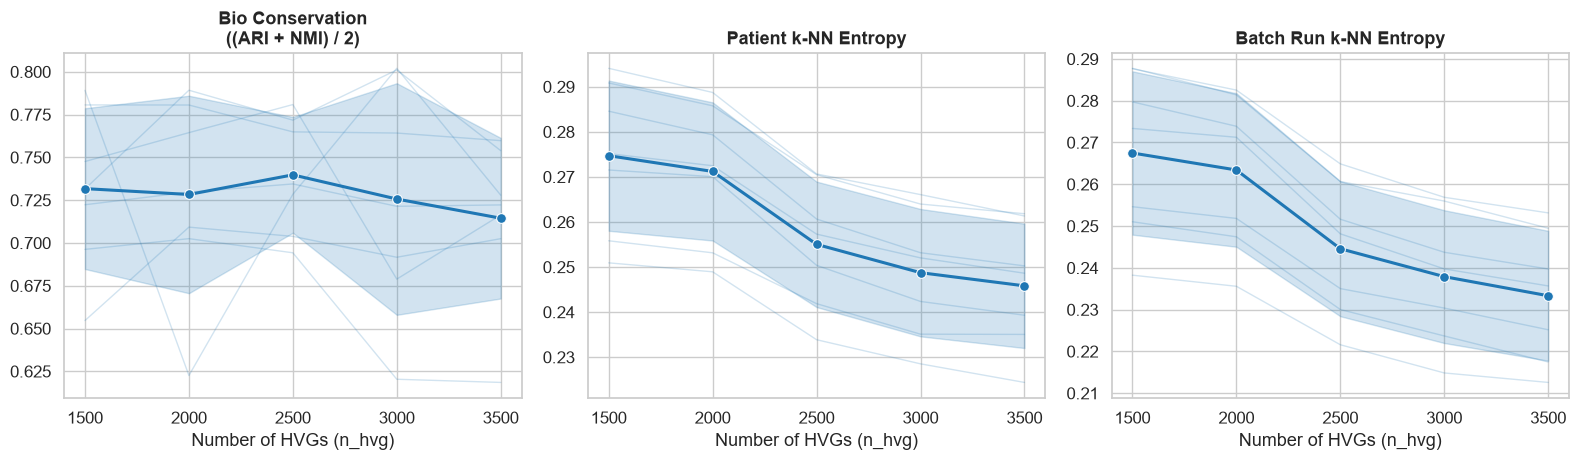

In [ ]:
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.1)

metrics = [
    ("bio", "Bio Conservation ((ARI + NMI) / 2)"),
    ("Patient_Entropy", "Patient k-NN Entropy"),
    ("Batch_Run_Entropy", "Batch Run k-NN Entropy"),
]

# Plotting
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharex=True)

modes = res["mode"].unique()
palette = dict(zip(modes, sns.color_palette("tab10", len(modes))))
xticks = sorted(res["n_hvg"].unique())

for ax, (col, title) in zip(axes, metrics):
    # Individual seeds
    for mode in modes:
        sub = res[res["mode"] == mode]
        for _, seed_df in sub.groupby("seed"):
            seed_df = seed_df.sort_values("n_hvg")
            ax.plot(
                seed_df["n_hvg"], seed_df[col],
                color=palette[mode], alpha=0.2, linewidth=1
            )

    # Mean and standard deviation
    sns.lineplot(
        data=res, x="n_hvg", y=col, hue="mode",
        palette=palette, marker="o", markersize=7, linewidth=2.2,
        errorbar="sd", err_style="band", ax=ax, legend=(ax == axes[0])
    )
    ax.set_title(title, fontweight="bold")
    ax.set_ylabel("")
    ax.set_xlabel("Number of HVGs (n_hvg)")
    ax.set_xticks(xticks)

if len(modes) > 1:
    axes[0].legend(title="HVG Mode", frameon=True)
elif axes[0].get_legend() is not None:
    axes[0].get_legend().remove()

plt.tight_layout()
plt.show()

2500 seems to be the optimal value. It provides the highest bio conservation values. Additionally, entropy while its entropy value is in the middle across the evaluated methods, this seems like a good starting point as we are not reducing that many genes (1500) and since it provides the best bio values, methods such as scVI or MrVI may benefit from this adjusting for patients.

## N_LATENT

We will now test PCA which is a linear model across different Latent dimensions to see how well it actually performs. As PCA uses a linear projection, it will require more dimensions to capture the complexity of this data, contrary to a non-linear model such as scVI or MrVI. Additionally, methods like MrVI are able of deactivating extra dimensions if they do not need it for their analysis. Finally, PCA is much simpler to compute therefore it seems like a reasonable baseline to decide the number of latent dimensions to use.

In [ ]:
# Using a subsample of data, this can extrapolate to the whole dataset
# Evaluating batch entropy of k neighbors is really expensive for this number of cells.
sub_size = min(20000, adata.n_obs)
adata_sub = sc.pp.subsample(adata, n_obs=sub_size, copy=True, random_state=SEED)
adata_sub.X = adata_sub.X.astype(np.float32)

# PCA on 50 components, later we just slice based on the remainng ones, another benefit of using PCA
MAX_COMPONENTS = 50
sc.pp.scale(adata_sub, max_value=10)
sc.tl.pca(adata_sub, n_comps=MAX_COMPONENTS, random_state=SEED)

# Evaluation targets from subsample
celltypes = adata_sub.obs["celltype"].values
patients = adata_sub.obs["patient"].values
run = adata_sub.obs["batch_run"].values
n_clusters = adata_sub.obs["celltype"].nunique()

# Different numbere of components
n_components_range = range(5, 51, 5)
results = []

for n in n_components_range:
    X_pca_n = adata_sub.obsm["X_pca"][:, :n]
    metrics = eval_rep(
        X_pca=X_pca_n,
        celltypes=celltypes,
        patients=patients,
        n_clusters=n_celltypes,
        batch_run=run
    )
    metrics["n_components"] = n
    results.append(metrics)

results_df = pd.DataFrame(results).set_index("n_components")
print(results_df)

              ARI_celltype  NMI_celltype  Patient_Entropy  Batch_Run_Entropy
n_components                                                                
5                    0.721         0.732            0.514              0.529
10                   0.688         0.744            0.375              0.377
15                   0.711         0.769            0.344              0.343
20                   0.711         0.763            0.332              0.329
25                   0.717         0.775            0.320              0.316
30                   0.703         0.766            0.306              0.300
35                   0.702         0.768            0.303              0.296
40                   0.749         0.790            0.300              0.293
45                   0.719         0.779            0.298              0.290
50                   0.549         0.727            0.296              0.289


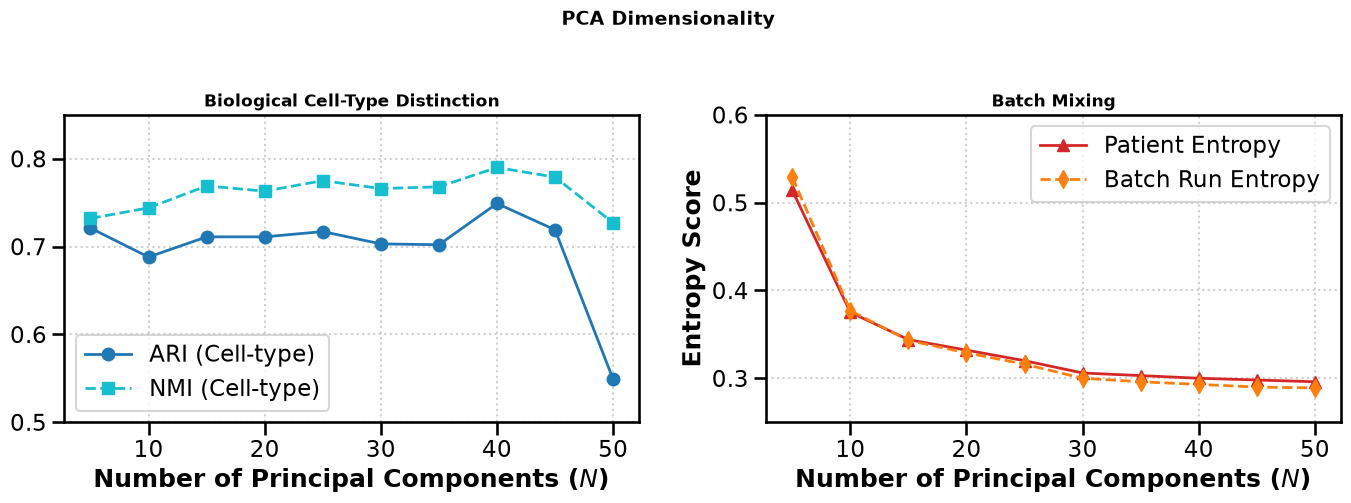

In [16]:
# Plotting the result
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1
ax1.plot(
    results_df.index,
    results_df["ARI_celltype"],
    marker="o",
    linewidth=2,
    label="ARI (Cell-type)",
    color="#1f77b4",
)
ax1.plot(
    results_df.index,
    results_df["NMI_celltype"],
    marker="s",
    linewidth=2,
    linestyle="--",
    label="NMI (Cell-type)",
    color="#17becf",
)

ax1.set_xlabel("Number of Principal Components ($N$)", fontweight="bold")
ax1.set_title("Biological Cell-Type Distinction", fontweight="bold", fontsize=12)
ax1.set_ylim(0.50, 0.85)
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="lower left")

# Batch Mixing
ax2.plot(
    results_df.index,
    results_df["Patient_Entropy"],
    marker="^",
    linewidth=2,
    label="Patient Entropy",
    color="#d62728",
)
ax2.plot(
    results_df.index,
    results_df["Batch_Run_Entropy"],
    marker="d",
    linewidth=2,
    linestyle="--",
    label="Batch Run Entropy",
    color="#ff7f0e",
)

ax2.set_xlabel("Number of Principal Components ($N$)", fontweight="bold")
ax2.set_ylabel("Entropy Score", fontweight="bold")
ax2.set_title("Batch Mixing", fontweight="bold", fontsize=12)
ax2.set_ylim(0.25, 0.60)
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="upper right")


plt.suptitle(
    "PCA Dimensionality",
    fontweight="bold",
    fontsize=14,
    y=1.02,
)
plt.tight_layout()
plt.show()



By looking at the plot and the different metrics. We can see that across all components, ARI and NMI is in the 0.7 region. It shows a clear rise for N=40, and a big performance drop for N=50. Moreover, its entropy values are somewhat correct.

N=5 actually shows really good metrics, however, this seem more like pure randomness as if we were to compress our space into just 5 dimensions, distinct populations end up overlapping each other because there is not enough space to separate them rather than by biological differences. Additionally, its NMI is the lowest as it cannot evaluate well cell sub-types.

However, we have the same problem as before, this is done across one random seed which could show reasonable values just from luck. Therefore, we will use many different seeds to provide robustness.

In [ ]:
N_HVG          = 2500
SEEDS          = [0, 1, 2, 3, 4, 5, 6]
N_EVAL         = 20_000
PAT_FRAC       = 0.8
MAX_COMPONENTS = 50
N_PCS_RANGE    = list(range(5, 51, 5))
REF_PCS        = 30   # perform comparison

# Select the 2500 patient-aware HVGs 
genes = hvg_list(N_HVG, "patient")

ct      = adata.obs["celltype"].astype(str).values
pat     = adata.obs["patient"].astype(str).values
run     = adata.obs["batch_run"].astype(str).values
all_pat = np.unique(pat)

# Iterating through the seeds
rows = []
for s in SEEDS:
    rng = np.random.default_rng(s)
    keep_p = rng.choice(all_pat, int(PAT_FRAC * len(all_pat)), replace=False)
    pool = np.where(np.isin(pat, keep_p))[0]
    idx = np.sort(rng.choice(pool, min(N_EVAL, len(pool)), replace=False))

    # Subset to selected cells and 2500 HVGs, using log-normalized expression
    adata_sub = adata[idx, genes].copy()
    if "lognorm" in adata_sub.layers:
        adata_sub.X = adata_sub.layers["lognorm"]
    adata_sub.X = adata_sub.X.astype(np.float32)

    # Performing the PCA
    sc.pp.scale(adata_sub, max_value=10)
    sc.tl.pca(adata_sub, n_comps=MAX_COMPONENTS, random_state=s)

    X_pca_full = adata_sub.obsm["X_pca"]
    ct_sub     = ct[idx]
    pat_sub    = pat[idx]
    run_sub    = run[idx]
    n_ct_sub   = len(np.unique(ct_sub))

    # Evaluating
    for n in N_PCS_RANGE:
        m = eval_rep(
            X_pca=X_pca_full[:, :n],
            celltypes=ct_sub,
            patients=pat_sub,
            n_clusters=n_ct_sub,
            batch_run=run_sub,
            seed=s,
        )
        rows.append({"n_components": n, "seed": s, **m})

    print(f"done seed {s}", flush=True)

res = pd.DataFrame(rows)
ari_col = "ARI_celltype" if "ARI_celltype" in res.columns else "ARI"
nmi_col = "NMI_celltype" if "NMI_celltype" in res.columns else "NMI"
res["bio"] = (res[ari_col] + res[nmi_col]) / 2

# Summary table showing mean and std
cols = [ari_col, nmi_col, "bio", "Patient_Entropy", "Batch_Run_Entropy"]
print(res.groupby("n_components")[cols].agg(["mean", "std"]).round(3))

# Computes difference to ref pcs used
ref = res[res["n_components"] == REF_PCS].set_index("seed")["bio"]
res["d_bio"] = res["bio"] - res["seed"].map(ref)
print("\nPaired Δ bio vs.", REF_PCS, "PCs:")
print(res.groupby("n_components")["d_bio"].agg(["mean", "std"]).round(3))

done seed 0
done seed 1
done seed 2
done seed 3
done seed 4
done seed 5
done seed 6
             ARI_celltype        NMI_celltype           bio         \
                     mean    std         mean    std   mean    std   
n_components                                                         
5                   0.653  0.054        0.708  0.033  0.681  0.042   
10                  0.714  0.037        0.752  0.022  0.733  0.025   
15                  0.709  0.037        0.758  0.013  0.734  0.023   
20                  0.705  0.037        0.756  0.013  0.730  0.023   
25                  0.706  0.058        0.756  0.041  0.731  0.048   
30                  0.707  0.039        0.758  0.027  0.732  0.031   
35                  0.699  0.068        0.757  0.017  0.728  0.038   
40                  0.723  0.061        0.767  0.020  0.745  0.038   
45                  0.723  0.042        0.770  0.030  0.747  0.034   
50                  0.732  0.055        0.768  0.022  0.750  0.034   

     

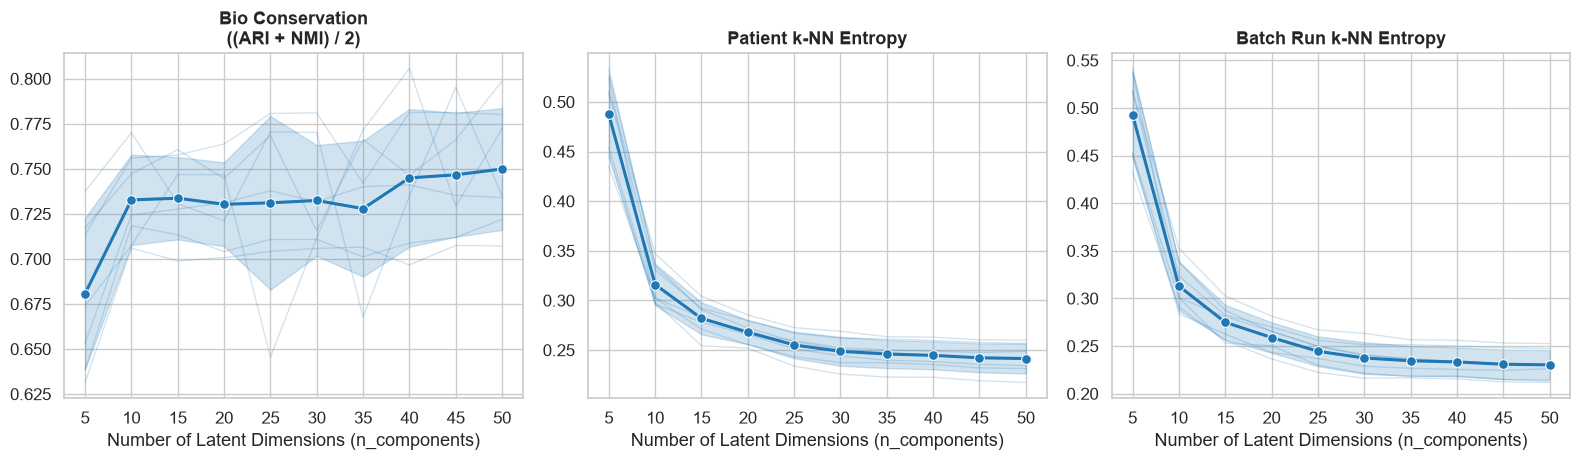

In [ ]:
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.1)
main_color = sns.color_palette("tab10")[0]

metrics = [
    ("bio", "Bio Conservation\n((ARI + NMI) / 2)"),
    ("Patient_Entropy", "Patient k-NN Entropy"),
    ("Batch_Run_Entropy", "Batch Run k-NN Entropy"),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharex=True)
xticks = sorted(res["n_components"].unique())

for ax, (col, title) in zip(axes, metrics):
    # Individual seed trajectories
    for _, seed_df in res.groupby("seed"):
        seed_df = seed_df.sort_values("n_components")
        ax.plot(
            seed_df["n_components"], seed_df[col],
            color=main_color, alpha=0.2, linewidth=1
        )

    # Mean and std across seeds
    sns.lineplot(
        data=res, x="n_components", y=col,
        color=main_color, marker="o", markersize=7, linewidth=2.2,
        errorbar="sd", err_style="band", ax=ax
    )
    ax.set_title(title, fontweight="bold")
    ax.set_ylabel("")
    ax.set_xlabel("Number of Latent Dimensions (n_components)")
    ax.set_xticks(xticks)

plt.tight_layout()
plt.show()

10 latents seems to be the best choice. We see that values such as 40 or 50 may be better for finer subpopulations but our current idea is to implement it for each of the cell types. Additionally, this is a big dimensionality reduction which seems pretty important. They show the highest difference in Bio metrics, moreover, their entropy is also among the highest. 15 could also be chosen, but 10 seems reasonable to work with, so we will stick with it.

# Baseline Model (PCA)

We will apply PCA on log-normalized data as a baseline model to compare with the remaining models. We have already done certain experiments with it. 

Principal Component Analysis (PCA) transforms data into new features (principal components). It does this by calculating eigenvectors and eigenvalues from the covariance matrix. The highest eigenvalues are then used to select the top components. 

In short, PCA uses a linear transformation based on preserving the most variance of data (information) using the least number of dimensions.


In [10]:
from src import data as D       
from src import hvg as H        
from src import metrics as M    
from src import splits as S     
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt


###  Load data and attach the folds

`load_adata()` finds `wu2021_brca.h5ad` automatically and fixes the layout: in the file `.X` is
already log1p-CP10k and the counts are in `.raw`, so after loading `adata.X` = **raw integer counts**
(what scVI/MrVI and seurat_v3 HVG need) and `adata.layers["lognorm"]` = log1p-CP10k (for PCA-like
baselines). Never apply `log1p` again. `attach_folds()` reads
`data/splits.parquet` (the 26-patient table from notebook 01) and maps each patient's
`fold_5 / fold_lopo / fold_batch` onto every cell via `donor_id`.

In [2]:
adata = D.load_adata()  # the real data: cells x genes
D.attach_folds(adata) # adds obs['fold_5'], obs['fold_lopo'], obs['fold_batch']
print(adata)
adata.obs[['donor_id','fold_5','fold_lopo','fold_batch']].drop_duplicates('donor_id').head() # Safety head drop duplicates

AnnData object with n_obs × n_vars = 100064 × 28523
    obs: 'donor_id', 'percent_mito', 'nCount_RNA', 'nFeature_RNA', 'celltype_major', 'celltype_minor', 'celltype_subset', 'subtype', 'gene_module', 'calls', 'normal_cell_call', 'CNA_value', 'batch_run', 'multiplexed', 'cryo_state', 'development_stage_ontology_term_id', 'cancer_type', 'ER', 'PR', 'HER2_IHC', 'HER2_ISH', 'HER2_ISH_ratio', 'Ki67', 'subtype_by_IHC', 'treatment_status', 'treatment_details', 'assay_ontology_term_id', 'tissue_ontology_term_id', 'suspension_type', 'sex_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'is_primary_data', 'disease_ontology_term_id', 'grade', 'cell_type_ontology_term_id', 'tissue_type', 'HER2_ISH_legacy', 'cell_type_ontology_term_id_legacy', 'celltype_major_legacy', 'celltype_minor_legacy', 'celltype_subset_legacy', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid', 'fold_5', 'fold_lopo', 'fold_batch'
    var: 'fea

,donor_id,fold_5,fold_lopo,fold_batch
CID3586_AAGACCTCAGCATGAG,CID3586,3,0,13
CID3921_AAAGATGGTGAGGCTA,CID3921,2,2,12
CID45171_CATCAAGTCAACACCA,CID45171,4,25,9
CID3838_AAACGCTAGAGCCGAT,CID3838,1,1,16
CID4066_ACTGCTCTCTCGATGA,CID4066,0,8,12


###  Fold

`fold_mask(adata, scheme, test_value)` returns boolean `train_mask, test_mask` with no cell
of a patient split across the two. We then select HVG on train only (`select_hvg_train`)
so feature selection never sees the test patient.

In [3]:
SCHEME, TEST_FOLD = "fold_5", 0
train_mask, test_mask = D.fold_mask(adata, SCHEME, TEST_FOLD)
print(f"{SCHEME}=={TEST_FOLD}:  train cells = {train_mask.sum():,}   test cells = {test_mask.sum():,}")

N_HVG = 2500
hvg = H.select_hvg_train(adata, train_mask, n_top=N_HVG) # computed on TRAIN cells only
print("HVG selected on train:", len(hvg))

fold_5==0:  train cells = 78,344   test cells = 21,720
HVG selected on train: 2503


In [8]:
N_LATENT = 10

def _dense(X):
    return X.toarray() if hasattr(X, "toarray") else np.asarray(X)

def fit_pca(adata_tr, n_comps=N_LATENT, seed=S.SEED):
    """Same recipe as the baseline: sc.pp.scale(max_value=10) + sc.tl.pca, on TRAIN cells only."""
    a = adata_tr.copy()
    X = a.layers["lognorm"]                  # log1p data
    a.X = _dense(X).astype(np.float32)

    sc.pp.scale(a, max_value=10)           # stores train mean/std in a.var["mean"], a.var["std"]
    sc.tl.pca(a, n_comps=n_comps, random_state=seed)

    sd = np.asarray(a.var["std"].values, dtype=np.float32)
    sd[sd == 0] = 1.0
    return {
        "mu": np.asarray(a.var["mean"].values, dtype=np.float32),   # train gene means 
        "sd": sd,                                                   # train gene stds
        "center": _dense(a.X).mean(0),                              # train mean of the scaled data
        "PCs": np.asarray(a.varm["PCs"], dtype=np.float32),         # genes x n_comps loadings
        "var_ratio": a.uns["pca"]["variance_ratio"],
        "X_pca_train": a.obsm["X_pca"].astype(np.float32),
    }

def project_pca(model, adata_any):
    """Project cells with the train scaling and loadings."""
    X = _dense(adata_any.layers["lognorm"]).astype(np.float32)     
    Xs = np.minimum((X - model["mu"]) / model["sd"], 10)         
    return ((Xs - model["center"]) @ model["PCs"]).astype(np.float32)


adata_train = adata[train_mask, hvg].copy()
adata_test  = adata[test_mask, hvg].copy()

pca_model = fit_pca(adata_train)


Z = np.zeros((adata.n_obs, N_LATENT), dtype=np.float32)
Z[train_mask] = pca_model["X_pca_train"]
Z[test_mask]  = project_pca(pca_model, adata_test)   # Test data
adata.obsm["X_pca"] = Z
adata_train.obsm["X_pca"] = Z[train_mask]
print(f"Z: {Z.shape}")

Z: (100064, 10)


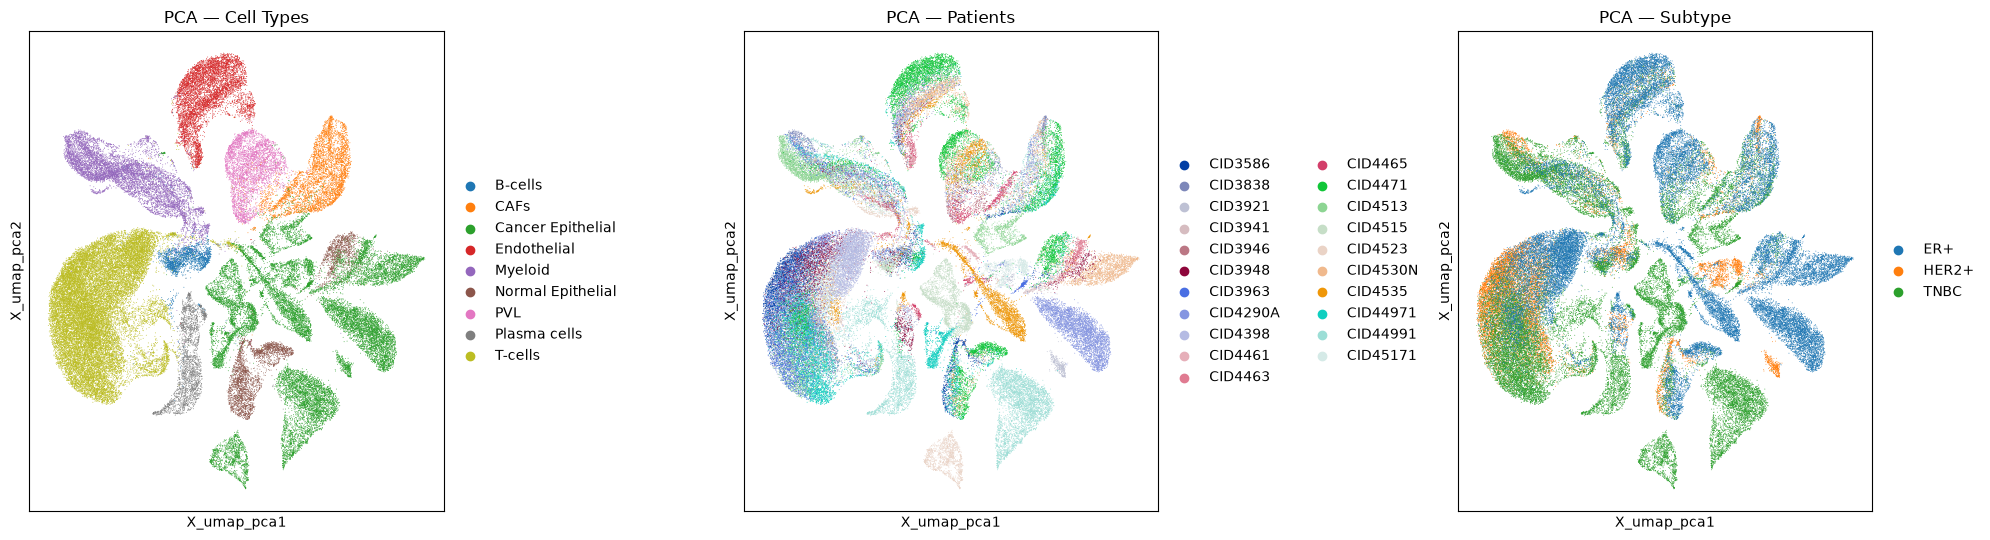

In [12]:
sc.pp.neighbors(adata_train, use_rep="X_pca", key_added="pca_neighbors")
sc.tl.umap(adata_train, neighbors_key="pca_neighbors")
adata_train.obsm["X_umap_pca"] = adata_train.obsm["X_umap"].copy()

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, (col, title) in zip(axes, [("celltype_major", "PCA — Cell Types"),
                                   ("donor_id", "PCA — Patients"),
                                   ("subtype", "PCA — Subtype")]):
    if col in adata_train.obs:
        sc.pl.embedding(adata_train, basis="X_umap_pca", color=col, ax=ax, show=False, title=title)
    else:
        ax.axis("off")
plt.tight_layout(); plt.show()

### Evaluation Metrics

The metrics we will use to evaluate the model will be applied at latent space level.They will be used to asses the quality of preserving cell-type identity as well as integrating patient samples. They are taken from some of the papers in the literature such as the Benchmarking paper [M.D. Luecken et. Al.](https://www.nature.com/articles/s41592-021-01336-8).
These are:

- **[Adjusted Rand Index (ARI)](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html)**:  Evaluates the similarity between two clustering assignments. Takes the Rand Index (RI) which computes the percentage of correct decisions comparing the predicted clusters to the true labels. In our case, we compare to the true cell-type labels. However, random assignments could have positive values, which is addressed by Adjusted Rand Index. Returns a value between -1 and 1. 1 means perfect classification, 0 corresponds to random cluster assignment

- **[Normalized Mutual Information (NMI)](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.normalized_mutual_info_score.html)**: Mutual Information splits according to clusters and according to class labels. Then, it quantifies how these two splittings agree with each other. However, MI gets large if the number of clusters is large. Therefore, this number is normalized to be between 0 (no mutual information) and 1 (perfect correlation). The higher the better

- **[Average Silhouette Width (ASW)](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html)**: Measures how close an element is to its own cluster while comparing to its other clusters. Returns a value between -1 and 1, where negative values will correspond to when a sample has been assigned to the wrong cluster, positive values indicate good clustering. Values close to 0 are for overlapping clusters.

    The intepretation for this value depends on whether if we want to inspect quality of preserving cell-type identity or integrating patient samples.
    *ASW (cell):* The grouping variable will be the cell-type, we want this value to be high as cells of the same type should form isolated clusters in latent space.
    *ASW(patient):* If this value is high, it means that cells are clustering by patient rather than by biology elements.Therefore we want values closer to 0, as patients contain technical effects, which are usually unwanted (technical effects could be being inspected by a different doctor, different hospital, different times...)

- **Batch Entropy**: Measures the local mixing of a label in the k-nearest neighbor (kNN) graph around each cell. For every cell, the algorithm creates a neighborhood of its k nearest neighbors. (In the below function we use k=50, this will be the same for all models). A low value means that a cell neighborhood has cells from a single label.This can be used to compute for patients -> 'labels=adata.obs["batch_run"]' or 'labels=adata.obs["batch_run"]' are some of the possible options. 

    Our current batch entropy evaluates K=50 neighbors, as we have less number of patients and batch runs, is is possible that the theoretical maximum is slightly lower than 1, we will compute it so we can use it for reference when we obtain values.

In [13]:
te = test_mask
scores = M.evaluate_embedding(
    Z=Z[te],
    cell_type=adata.obs["celltype_major"].values[te],
    patient=adata.obs["donor_id"].values[te],
    batch_run=adata.obs["batch_run"].values[te],
    k=50,
    asw_sample_size=20000,
    seed=S.SEED,
)
print("test fold", TEST_FOLD, "->", {k: round(v, 3) for k, v in scores.items()})

test fold 0 -> {'ARI': 0.743, 'NMI': 0.778, 'ASW_celltype': 0.679, 'ASW_patient': 0.049, 'Patient_Entropy': 0.243, 'Batch_Run_Entropy': 0.243}


We see high values around 0.75 for both ARI and NMI. Suggesting that despite its linearity, PCA actually captures an important amount of information from the dataset and it is able to preserve cell-type identity. This is further supported by ASW, as with respect to the cell its value is positive suggesting that it is indeed clustering by cell type, moreover, when taking into account the Patient its values are around 0, suggesting that patients do not form clear clusters.

Entropy of PCA however is not too strong. Values close to 0.24 for both patient and batch run. Therefore, technical factors still have a certain influence on the clustering as there is no overlap between patients and batch runs at least on k=50 neighbors. Eventually, the linearity of PCA fails to remove technical batch/patient identity, therefore other models could show further improvements

However, we will perform 5 fold cross validation in order to provide robustness. This 5 fold cross-validation 

###  Loop over every fold (cross-validation)

`iter_folds` yields `(test_value, train_mask, test_mask)` for the whole scheme. 

In [14]:
rows = []
SPLIT_NAMES = {"fold_5": "5fold", "fold_batch": "lobo", "fold_lopo": "lopo"}
split_tag = SPLIT_NAMES.get(SCHEME, SCHEME)

for test_value, tr, te in D.iter_folds(adata, scheme=SCHEME):
    hvg_k = H.select_hvg_train(adata, tr, n_top=N_HVG)

    adata_tr = adata[tr, hvg_k].copy()
    adata_te = adata[te, hvg_k].copy()
    m_k = fit_pca(adata_tr)
    Z_te = project_pca(m_k, adata_te)

    s = M.evaluate_embedding(
        Z=Z_te,
        cell_type=adata.obs["celltype_major"].values[te],
        patient=adata.obs["donor_id"].values[te],
        batch_run=adata.obs["batch_run"].values[te],
        k=50,
        seed=S.SEED,
    )
    s["fold"] = test_value
    rows.append(s)

res = pd.DataFrame(rows).set_index("fold")
print(res.round(3))
print("\nMEAN:", res.mean(numeric_only=True).round(3).to_dict())
print("STD :", res.std(numeric_only=True).round(3).to_dict())

        ARI    NMI  ASW_celltype  ASW_patient  Patient_Entropy  \
fold                                                             
3     0.827  0.734         0.640        0.029            0.316   
2     0.619  0.724         0.683        0.027            0.228   
4     0.773  0.779         0.685        0.044            0.152   
1     0.708  0.772         0.692        0.047            0.239   
0     0.743  0.778         0.679        0.049            0.243   

      Batch_Run_Entropy  
fold                     
3                 0.304  
2                 0.228  
4                 0.152  
1                 0.239  
0                 0.243  

MEAN: {'ARI': 0.734, 'NMI': 0.757, 'ASW_celltype': 0.676, 'ASW_patient': 0.039, 'Patient_Entropy': 0.236, 'Batch_Run_Entropy': 0.233}
STD : {'ARI': 0.078, 'NMI': 0.026, 'ASW_celltype': 0.021, 'ASW_patient': 0.011, 'Patient_Entropy': 0.058, 'Batch_Run_Entropy': 0.054}


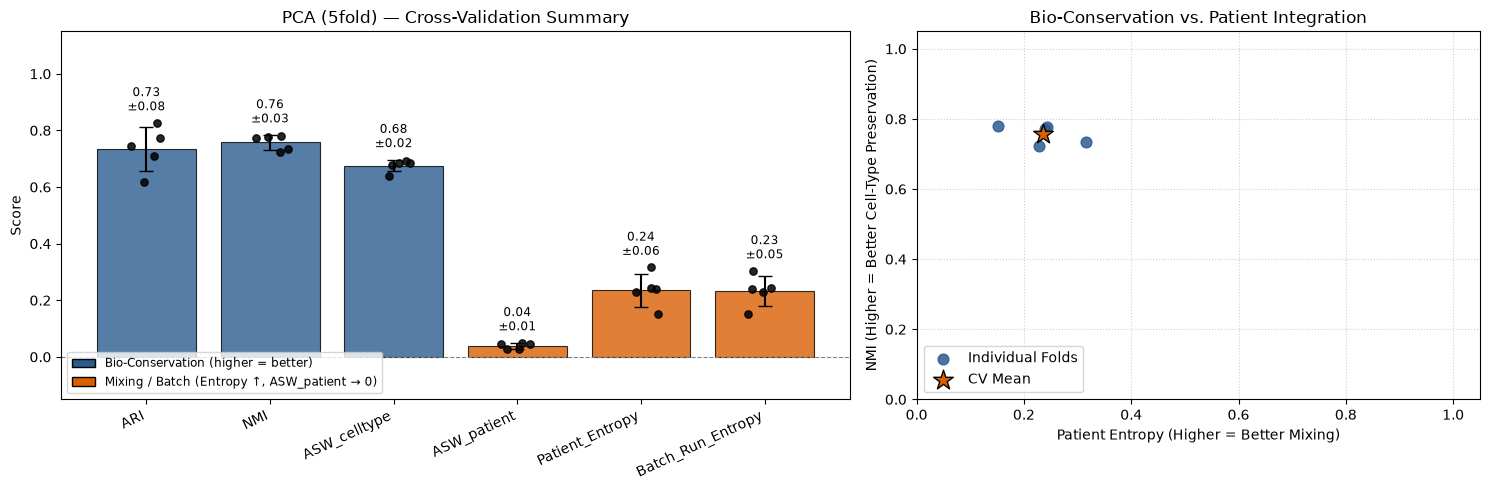

In [15]:
res_plot = res.copy()
metrics = list(res_plot.columns)
means, stds = res_plot[metrics].mean(), res_plot[metrics].std()

bio_metrics = {"ARI", "NMI", "ASW_celltype"}
colors = ["#2b5c8f" if m in bio_metrics else "#d95f02" for m in metrics]

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.4, 1]})

ax = axes[0]
x = np.arange(len(metrics))
ax.bar(x, means, yerr=stds, capsize=5, color=colors, alpha=0.8, edgecolor="black", linewidth=0.8)
rng = np.random.default_rng(S.SEED)
for i, m in enumerate(metrics):
    jitter = rng.uniform(-0.15, 0.15, size=len(res_plot))
    ax.scatter(np.full(len(res_plot), i) + jitter, res_plot[m], color="black", s=28, zorder=3, alpha=0.85)
    top = max(means[m] + (stds[m] if not np.isnan(stds[m]) else 0), res_plot[m].max())
    ax.text(i, top + 0.03, f"{means[m]:.2f}\n±{stds[m]:.2f}", ha="center", va="bottom", fontsize=8.5)
ax.axhline(0, color="gray", linewidth=0.8, linestyle="--")
ax.set_xticks(x); ax.set_xticklabels(metrics, rotation=25, ha="right")
ax.set_ylim(min(-0.15, res_plot.min().min() - 0.1), 1.15)
ax.set_ylabel("Score")
ax.set_title(f"PCA ({split_tag}) — Cross-Validation Summary")
from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(facecolor="#2b5c8f", edgecolor="black", label="Bio-Conservation (higher = better)"),
    Patch(facecolor="#d95f02", edgecolor="black", label="Mixing / Batch (Entropy ↑, ASW_patient → 0)"),
], loc="lower left", fontsize=8.5)

ax2 = axes[1]
ax2.scatter(res_plot["Patient_Entropy"], res_plot["NMI"], color="#2b5c8f", s=60, alpha=0.85, label="Individual Folds")
ax2.scatter(means["Patient_Entropy"], means["NMI"], color="#d95f02", marker="*", s=220,
            edgecolor="black", zorder=4, label="CV Mean")
ax2.set_xlim(0, 1.05); ax2.set_ylim(0, 1.05)
ax2.set_xlabel("Patient Entropy (Higher = Better Mixing)")
ax2.set_ylabel("NMI (Higher = Better Cell-Type Preservation)")
ax2.set_title("Bio-Conservation vs. Patient Integration")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="lower left")

plt.tight_layout(); plt.show()

# Conclusions

5 Fold Patient Validation, which is stratified on cancer subtype returned reasonably good values, of bio conservation values around 0.75. High ASW celltype compared to a lower ASW patient. Finally, Patient and Batch run entropy was around 0.23.

This shows that despite the simplicity of PCA it is capable of making distinctions among cells in a 10 dimensional latent space.